<a href="https://colab.research.google.com/github/ilsafaisal15/Heuristic-Graph-Pathfinding-Agent-Search-Engine/blob/main/Task2_Pathfinding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import heapq, time, random, os, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

os.makedirs("outputs", exist_ok=True)

In [ ]:
def make_grid(size, density, seed):
    """Random obstacle grid. Start (0,0) and goal (size-1,size-1) are always free."""
    rng = np.random.default_rng(seed)
    grid = (rng.random((size, size)) < density).astype(int)
    grid[0, 0] = 0
    grid[size-1, size-1] = 0
    return grid

def neighbors(grid, node):
    r, c = node
    for dr, dc in ((1,0),(-1,0),(0,1),(0,-1)):          # 4-connected moves
        nr, nc = r+dr, c+dc
        if 0 <= nr < grid.shape[0] and 0 <= nc < grid.shape[1] and grid[nr, nc] == 0:
            yield (nr, nc)

# Heuristics
def manhattan(a, b): return abs(a[0]-b[0]) + abs(a[1]-b[1])
def euclidean(a, b): return math.hypot(a[0]-b[0], a[1]-b[1])
def zero(a, b):      return 0     # turns A* into Dijkstra

In [ ]:
def best_first_search(grid, start, goal, heuristic):
    """Generic priority-queue search.
    f(n) = g(n) + h(n).  With h = 0 this is Dijkstra; with an admissible h it is A*.
    Returns a dict of metrics + the path + the order in which nodes were expanded."""
    t0 = time.perf_counter()
    counter = 0                                   # tie-breaker for heap
    open_heap = [(heuristic(start, goal), counter, start)]
    g = {start: 0}
    parent = {start: None}
    closed = set()
    expanded_order = []

    while open_heap:
        f, _, node = heapq.heappop(open_heap)
        if node in closed:
            continue
        closed.add(node)
        expanded_order.append(node)

        if node == goal:                          # reconstruct path
            path = []
            while node is not None:
                path.append(node)
                node = parent[node]
            path.reverse()
            return dict(found=True, path=path, steps=len(path)-1, cost=g[goal],
                        expanded=len(closed), expanded_order=expanded_order,
                        runtime_ms=(time.perf_counter()-t0)*1000)

        for nb in neighbors(grid, node):
            new_g = g[node] + 1
            if nb not in g or new_g < g[nb]:
                g[nb] = new_g
                parent[nb] = node
                counter += 1
                heapq.heappush(open_heap, (new_g + heuristic(nb, goal), counter, nb))

    return dict(found=False, path=[], steps=None, cost=None, expanded=len(closed),
                expanded_order=expanded_order, runtime_ms=(time.perf_counter()-t0)*1000)

def dijkstra(grid, s, g_): return best_first_search(grid, s, g_, zero)
def astar(grid, s, g_, h=manhattan): return best_first_search(grid, s, g_, h)

# Quick sanity test
test = make_grid(20, 0.2, seed=1)
r = astar(test, (0,0), (19,19))
print("A* found:", r["found"], "| steps:", r["steps"], "| expanded:", r["expanded"])

A* found: True | steps: 38 | expanded: 224


In [ ]:
SIZE = 50
DENSITIES = [0.10, 0.20, 0.30, 0.35, 0.40]
TRIALS = 20

algorithms = {
    "Dijkstra":        dijkstra,
    "A* (Manhattan)":  lambda gr, s, g_: astar(gr, s, g_, manhattan),
    "A* (Euclidean)":  lambda gr, s, g_: astar(gr, s, g_, euclidean),
}

rows = []
start, goal = (0, 0), (SIZE-1, SIZE-1)
for d in DENSITIES:
    for seed in range(TRIALS):
        grid = make_grid(SIZE, d, seed)
        for name, fn in algorithms.items():
            res = fn(grid, start, goal)
            rows.append(dict(density=d, seed=seed, algorithm=name, found=res["found"],
                             steps=res["steps"], expanded=res["expanded"],
                             node_density=res["expanded"]/(SIZE*SIZE),
                             runtime_ms=res["runtime_ms"]))

df = pd.DataFrame(rows)
df.to_csv("outputs/experiment_log.csv", index=False)

solved = df[df.found]
summary = (solved.groupby(["density", "algorithm"])
                 .agg(solved_runs=("found","count"), avg_steps=("steps","mean"),
                      avg_expanded=("expanded","mean"), avg_node_density=("node_density","mean"),
                      avg_runtime_ms=("runtime_ms","mean"))
                 .round(3).reset_index())
summary.to_csv("outputs/summary_metrics.csv", index=False)
summary

,density,algorithm,solved_runs,avg_steps,avg_expanded,avg_node_density,avg_runtime_ms
0,0.10,A* (Euclidean),20,98.0,2204.15,0.882,18.191
1,0.10,A* (Manhattan),20,98.0,1980.85,0.792,16.013
2,0.10,Dijkstra,20,98.0,2251.10,0.900,17.145
3,0.20,A* (Euclidean),20,98.1,1803.70,0.721,11.955
4,0.20,A* (Manhattan),20,98.1,1256.60,0.503,8.619
5,0.20,Dijkstra,20,98.1,1992.35,0.797,12.538
6,0.30,A* (Euclidean),10,102.8,1231.60,0.493,7.388
7,0.30,A* (Manhattan),10,102.8,689.50,0.276,3.971
8,0.30,Dijkstra,10,102.8,1664.10,0.666,8.588
9,0.35,A* (Euclidean),2,104.0,846.00,0.338,6.238


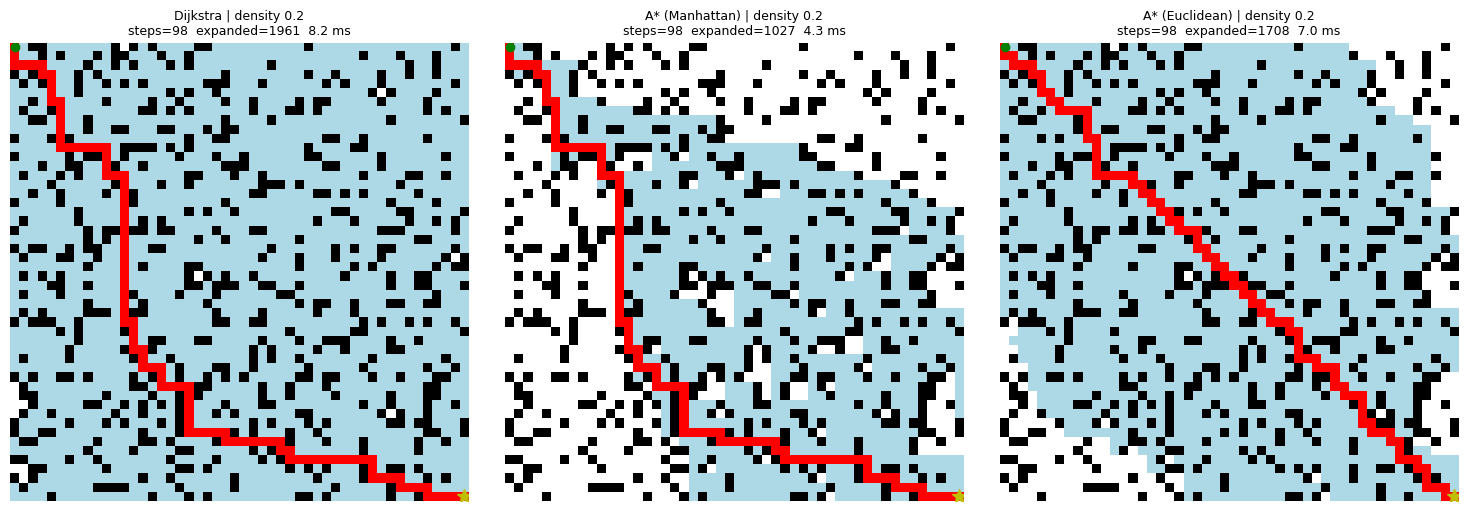

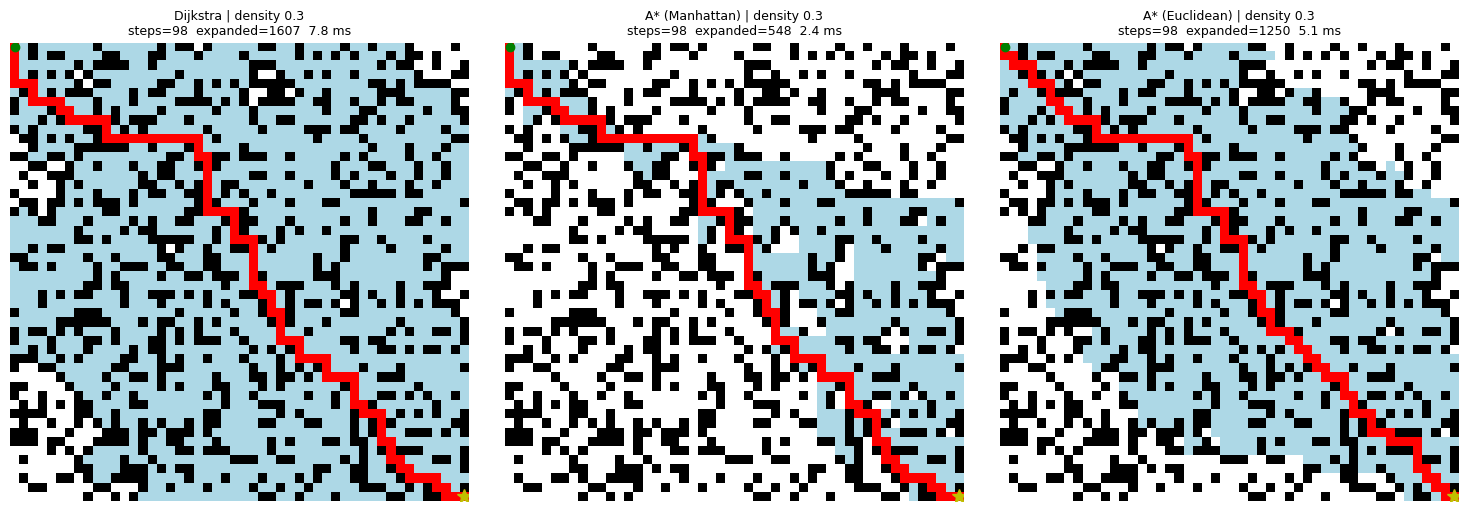

In [ ]:
def plot_search(grid, res, title, ax):
    img = grid.astype(float).copy()                 # 0 free, 1 wall
    for (r, c) in res["expanded_order"]:
        img[r, c] = 0.5                             # explored
    for (r, c) in res["path"]:
        img[r, c] = 0.75                            # final path
    cmap = ListedColormap(["white", "lightblue", "red", "black"])
    # map values: 0->white, 0.5->lightblue, 0.75->red, 1->black
    disp = np.zeros_like(img)
    disp[img == 0.5] = 1; disp[img == 0.75] = 2; disp[img == 1] = 3
    ax.imshow(disp, cmap=cmap, vmin=0, vmax=3)
    ax.set_title(f"{title}\nsteps={res['steps']}  expanded={res['expanded']}  {res['runtime_ms']:.1f} ms", fontsize=9)
    ax.axis("off")
    ax.plot(0, 0, "go"); ax.plot(grid.shape[1]-1, grid.shape[0]-1, "y*", markersize=10)

for d in [0.2, 0.3]:
    # find a solvable seed
    for seed in range(100):
        grid = make_grid(SIZE, d, seed)
        if dijkstra(grid, start, goal)["found"]:
            break
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, (name, fn) in zip(axes, algorithms.items()):
        plot_search(grid, fn(grid, start, goal), f"{name} | density {d}", ax)
    plt.tight_layout()
    plt.savefig(f"outputs/path_visualization_density_{d}.png", dpi=150)
    plt.show()

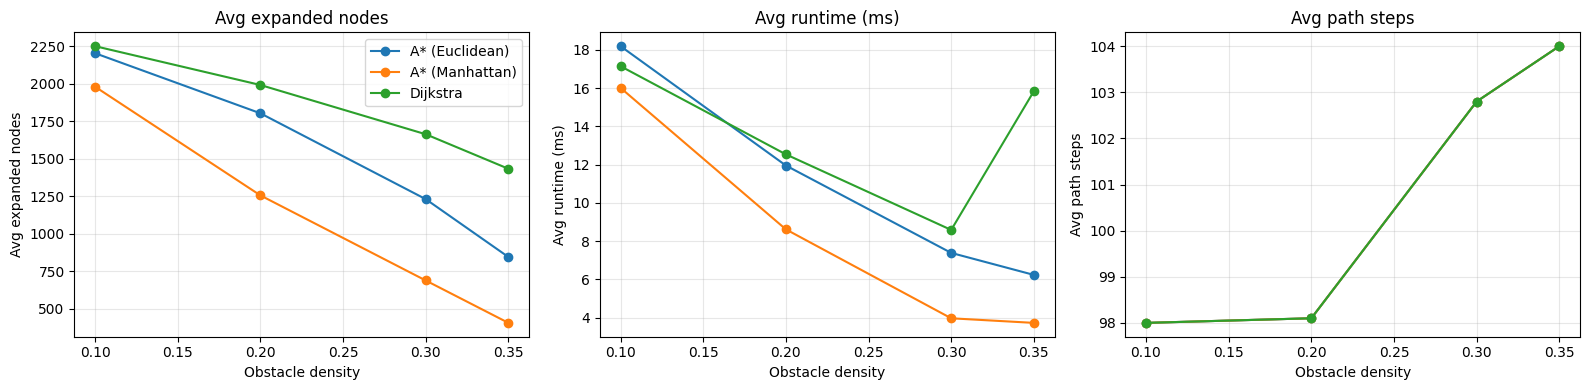

In [ ]:
# Metric comparison charts
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, label) in zip(axes, [("avg_expanded", "Avg expanded nodes"),
                                    ("avg_runtime_ms", "Avg runtime (ms)"),
                                    ("avg_steps", "Avg path steps")]):
    for name, sub in summary.groupby("algorithm"):
        ax.plot(sub["density"], sub[col], marker="o", label=name)
    ax.set_xlabel("Obstacle density"); ax.set_ylabel(label); ax.set_title(label); ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.savefig("outputs/metrics_comparison.png", dpi=150)
plt.show()

In [ ]:
import shutil
shutil.make_archive("pathfinding_results", "zip", "outputs")
try:
    from google.colab import files
    files.download("pathfinding_results.zip")
except ImportError:
    print("Not in Colab. Results are in ./outputs and pathfinding_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>